# Breakout Room #3 — Identificar los 4 cuadrantes

**Objetivo:**
- Detectar a los clientes que están en los cuatro cuadrantes.
- ¿Lograremos ver en cuáles es necesario invertir?

Esta es la base del experimento real de retención de Starbucks Rewards: 14,000 clientes, la mitad
recibió una oferta de retención (`treatment`), la otra mitad no (`control`) — asignados al azar.
Donde dice **`# TODO`** hay algo para que ustedes completen.


In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression

df = pd.read_csv("data/uplift_experiment.csv")
print(f"{len(df):,} clientes · {(df['treatment_group']=='treatment').sum():,} tratados · {(df['treatment_group']=='control').sum():,} control")
df.head()


14,000 clientes · 6,904 tratados · 7,096 control


,customer_id,treatment_group,recency_days,frequency,monetary,email_open_rate,responded_90d,value_90d
0,1,control,9,15,437.41,1.000,1,26.24
1,2,control,59,7,159.66,0.217,0,0.00
2,3,control,106,8,172.83,0.300,0,0.00
3,4,treatment,181,1,57.46,0.018,0,0.00
4,5,treatment,146,3,44.61,0.124,0,0.00


## Paso 1 — recuerden la fórmula de "uplift en una línea"

```
uplift(cliente) = P(compra | lo contacto) − P(compra | no lo contacto)
```

El problema: para UN cliente real, solo observamos una de las dos mitades (su contrafactual no
existe — ya lo vimos). La solución práctica: un **T-learner**. Entrenamos DOS modelos separados:

- Un modelo que solo vio clientes **tratados**, para estimar P(compra | lo contacto).
- Un modelo que solo vio clientes de **control**, para estimar P(compra | no lo contacto).

Después, le preguntamos a LOS DOS modelos sobre TODOS los clientes (tratados y de control por
igual) — así cada cliente termina con sus dos probabilidades, aunque en la realidad solo vivió una.


In [2]:
FEATURES = ["recency_days", "frequency", "monetary", "email_open_rate"]

tratados = df[df["treatment_group"] == "treatment"]
control = df[df["treatment_group"] == "control"]

print(f"Entrenamiento del modelo de tratados: {len(tratados):,} filas")
print(f"Entrenamiento del modelo de control:  {len(control):,} filas")


Entrenamiento del modelo de tratados: 6,904 filas
Entrenamiento del modelo de control:  7,096 filas


In [3]:
control.head()

,customer_id,treatment_group,recency_days,frequency,monetary,email_open_rate,responded_90d,value_90d
0,1,control,9,15,437.41,1.000,1,26.24
1,2,control,59,7,159.66,0.217,0,0.00
2,3,control,106,8,172.83,0.300,0,0.00
5,6,control,43,3,167.61,0.461,0,0.00
6,7,control,149,4,23.18,0.086,0,0.00


In [9]:
# TODO: entrenen los dos modelos del T-learner.
# modelo_tratado   se entrena SOLO con las filas de "tratados" (X=FEATURES, y=responded_90d)
# modelo_control  se entrena SOLO con las filas de "control"

modelo_tratado = LogisticRegression(max_iter=1000)
modelo_tratado.fit(
    tratados[FEATURES],
    tratados["responded_90d"]
)

modelo_control = LogisticRegression(max_iter=1000)
modelo_control.fit(
    control[FEATURES],
    control["responded_90d"]
)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

## Paso 2 — pregúntenle a los DOS modelos sobre TODOS los clientes

Aquí está el truco del T-learner: no importa si un cliente de verdad fue tratado o no, le pedimos
a `modelo_tratado` su probabilidad COMO SI lo hubieran tratado, y a `modelo_control` su
probabilidad COMO SI no lo hubieran tratado.


In [10]:
X_todos = df[FEATURES]

# TODO: calculen p_tratado (probabilidad de responder según modelo_tratado) y
# p_control (probabilidad de responder según modelo_control) para TODOS los clientes.
# Pista: modelo.predict_proba(X_todos)[:, 1] les da la probabilidad de la clase 1.

df["p_tratado"] = modelo_tratado.predict_proba(X_todos)[:, 1]
df["p_control"] = modelo_control.predict_proba(X_todos)[:, 1]

df["uplift_estimado"] = (
    df["p_tratado"] - df["p_control"]
)


## Paso 3 — clasifiquen a cada cliente en uno de los 4 cuadrantes

Usamos la mediana de cada probabilidad como punto de corte entre "alta" y "baja".


In [11]:
corte_tratado = df["p_tratado"].median()
corte_control = df["p_control"].median()

def cuadrante(row):
    alto_t = row["p_tratado"] >= corte_tratado
    alto_c = row["p_control"] >= corte_control
    if alto_t and alto_c:
        return "Sure Thing"
    if alto_t and not alto_c:
        return "Persuadable"
    if not alto_t and alto_c:
        return "Sleeping Dog"
    return "Lost Cause"

df["cuadrante"] = df.apply(cuadrante, axis=1)
df["cuadrante"].value_counts(normalize=True).rename("% de la base").mul(100).round(1)


cuadrante
Sure Thing      45.2
Lost Cause      45.2
Sleeping Dog     4.8
Persuadable      4.8
Name: % de la base, dtype: float64

## Paso 4 — ¿en cuáles es necesario invertir?

Comparen tres reglas de targeting, igual que en la slide de políticas: contactar al 30% con mayor
RIESGO de no responder (estilo churn) vs. contactar al 30% con mayor UPLIFT ESTIMADO vs. un 30% al
azar. Midan el valor real usando `value_90d`, comparando tratados contra control DENTRO de cada
grupo seleccionado

In [12]:
df.head()

,customer_id,treatment_group,recency_days,frequency,monetary,email_open_rate,responded_90d,value_90d,p_tratado,p_control,uplift_estimado,cuadrante
0,1,control,9,15,437.41,1.000,1,26.24,0.934143,0.676138,0.258005,Sure Thing
1,2,control,59,7,159.66,0.217,0,0.00,0.477361,0.310318,0.167043,Sure Thing
2,3,control,106,8,172.83,0.300,0,0.00,0.441871,0.268046,0.173825,Sleeping Dog
3,4,treatment,181,1,57.46,0.018,0,0.00,0.131832,0.102107,0.029725,Lost Cause
4,5,treatment,146,3,44.61,0.124,0,0.00,0.220318,0.121732,0.098586,Lost Cause


In [13]:
def valor_de_la_politica(seleccionados):
    sel = df.loc[seleccionados]
    valor_tratado = sel.loc[sel["treatment_group"] == "treatment", "value_90d"].mean()
    valor_control = sel.loc[sel["treatment_group"] == "control", "value_90d"].mean()
    return valor_tratado - valor_control, len(sel)

n_contactar = int(len(df) * 0.30)

# Regla 1: al azar
idx_azar = df.sample(n=n_contactar, random_state=42).index
uplift_azar, n_azar = valor_de_la_politica(idx_azar)

# Regla 2: por "riesgo" (al estilo churn) -- aquí lo aproximamos con p_control baja
# (baja probabilidad de comprar sin ayuda = "en riesgo")
idx_riesgo = df.sort_values("p_control").head(n_contactar).index
uplift_riesgo, n_riesgo = valor_de_la_politica(idx_riesgo)

# Regla 3: por uplift estimado (T-learner)
idx_uplift = df.sort_values("uplift_estimado", ascending=False).head(n_contactar).index
uplift_modelo, n_modelo = valor_de_la_politica(idx_uplift)

resultado = pd.DataFrame({
    "regla": ["Al azar", "Por riesgo (estilo churn)", "Por uplift (T-learner)"],
    "clientes_contactados": [n_azar, n_riesgo, n_modelo],
    "valor_incremental_por_cliente": [uplift_azar, uplift_riesgo, uplift_modelo],
})
resultado["valor_incremental_total"] = resultado["valor_incremental_por_cliente"] * resultado["clientes_contactados"]
resultado.round(2)


,regla,clientes_contactados,valor_incremental_por_cliente,valor_incremental_total
0,Al azar,4200,2.91,12238.69
1,Por riesgo (estilo churn),4200,0.30,1264.60
2,Por uplift (T-learner),4200,8.15,34229.38


## Paso 5 — la gráfica: composición del 30% seleccionado por cada regla


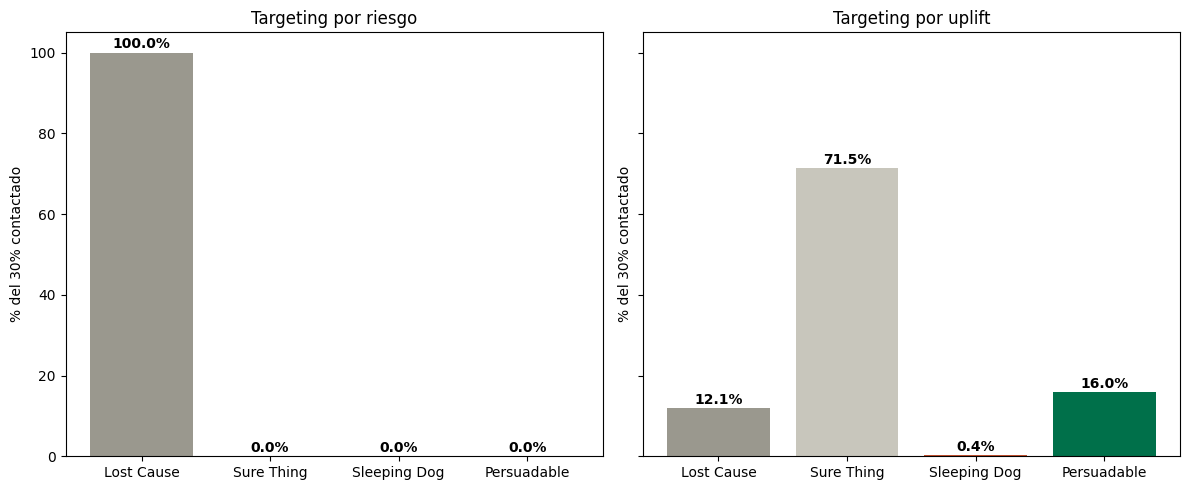

In [14]:
import matplotlib.pyplot as plt

comp_riesgo = df.loc[idx_riesgo, "cuadrante"].value_counts(normalize=True).reindex(
    ["Lost Cause", "Sure Thing", "Sleeping Dog", "Persuadable"]).fillna(0) * 100
comp_uplift = df.loc[idx_uplift, "cuadrante"].value_counts(normalize=True).reindex(
    ["Lost Cause", "Sure Thing", "Sleeping Dog", "Persuadable"]).fillna(0) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
colors = {"Lost Cause": "#9A988E", "Sure Thing": "#C8C6BC", "Sleeping Dog": "#C4512F", "Persuadable": "#00704A"}

for ax, comp, titulo in zip(axes, [comp_riesgo, comp_uplift], ["Targeting por riesgo", "Targeting por uplift"]):
    ax.bar(comp.index, comp.values, color=[colors[c] for c in comp.index])
    ax.set_title(titulo)
    ax.set_ylabel("% del 30% contactado")
    for i, v in enumerate(comp.values):
        ax.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.savefig("composicion_cuadrantes.png", dpi=150)
plt.show()


In [15]:
# Comparación de "tocar" o "no tocar" a un sleeping dog
sd = df[df["cuadrante"] == "Sleeping Dog"]
sd_t = sd.loc[sd["treatment_group"] == "treatment", "value_90d"].mean()
sd_c = sd.loc[sd["treatment_group"] == "control", "value_90d"].mean()
print(f"Sleeping Dogs: {len(sd):,} ({len(sd)/len(df):.1%} de la base)")
print(f"  valor si tratado=${sd_t:.2f}  valor si control=${sd_c:.2f}  efecto=${sd_t-sd_c:+.2f}")

Sleeping Dogs: 673 (4.8% de la base)
  valor si tratado=$17.49  valor si control=$18.98  efecto=$-1.48


## Para la Clase

1. ¿Qué regla dejó más valor incremental total: por riesgo o por uplift?

   Dejo mayor valor por uplift, con 8.15 por cada cliente vs el 0.30 en la regla por riesgo.

2. Miren la composición del 30% que targetea "por riesgo" — ¿cuántos Sleeping Dogs se colaron ahí? Eso es exactamente el costo de confundir "en riesgo" con "vale la pena contactar".

   En el grupo por riesgo no entro ningún Sleeping Dog, pero el 100% forman parte del grupo de causa perdida, por lo que de igual forma representa un costo por clientes que pase lo que pase no regresarán.

3. Con su propia tabla del Paso 4 en la mano: **¿en qué cuadrante es necesario invertir, y en cuál definitivamente NO?**

   Tomando de referencia la tabla, aunque el mayor porcentaje esta en el cuadrante de Sure Thing, estos clientes continuarán ya sea se les contacte o no, por lo que el grupo que más vale la pena invertir es en el persuadible, ya que es el segundo mayor grupo y es el que se obtendría un beneficio si se lorgan retener.